In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

print("TensorFlow Version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

TensorFlow Version: 2.21.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [7]:
import zipfile
import os

zip_path = "/content/archive.zip"
extract_path = "/content/brain_tumor_dataset"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print(os.listdir(extract_path))

Dataset extracted successfully!
['Testing', 'Training']


In [8]:
import os

base_path = "/content/brain_tumor_dataset"

for split in ["Training", "Testing"]:

    split_path = os.path.join(base_path, split)

    print(f"\n{split} Dataset:")

    for class_name in os.listdir(split_path):

        class_path = os.path.join(split_path, class_name)

        if os.path.isdir(class_path):

            images = [
                f for f in os.listdir(class_path)
                if f.lower().endswith((".jpg", ".jpeg", ".png"))
            ]

            print(class_name, ":", len(images), "images")


Training Dataset:
meningioma : 1400 images
pituitary : 1400 images
notumor : 1400 images
glioma : 1400 images

Testing Dataset:
meningioma : 400 images
pituitary : 400 images
notumor : 400 images
glioma : 400 images


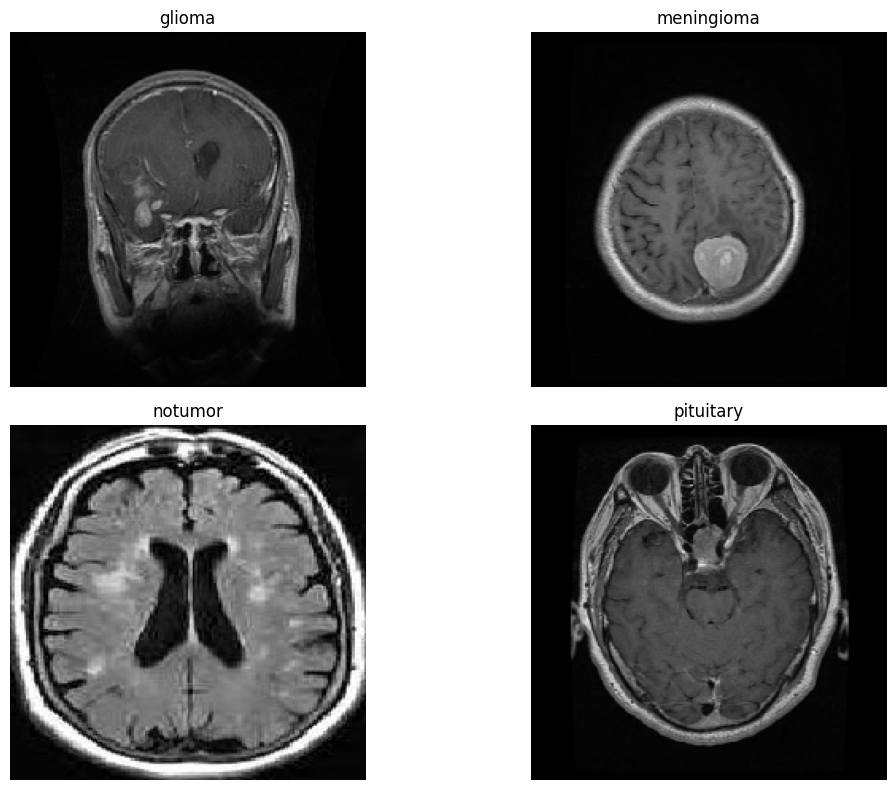

In [9]:
import matplotlib.pyplot as plt
from tensorflow.keras.utils import load_img

classes = ["glioma", "meningioma", "notumor", "pituitary"]

plt.figure(figsize=(12, 8))

for i, class_name in enumerate(classes):

    folder = os.path.join(base_path, "Training", class_name)

    image_name = os.listdir(folder)[0]
    image_path = os.path.join(folder, image_name)

    img = load_img(image_path, target_size=(224, 224))

    plt.subplot(2, 2, i + 1)
    plt.imshow(img)
    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [10]:
from PIL import Image

for class_name in classes:

    folder = os.path.join(
        "/content/brain_tumor_dataset",
        "Training",
        class_name
    )

    image_files = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    image_path = os.path.join(folder, image_files[0])

    img = Image.open(image_path)

    print(class_name, ":", img.size, img.mode)

glioma : (512, 512) RGB
meningioma : (512, 512) L
notumor : (150, 198) RGB
pituitary : (512, 512) RGB


In [12]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Augmentation only for training data
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=10,
    zoom_range=0.1,
    width_shift_range=0.1,
    height_shift_range=0.1,
    validation_split=0.2
)

# No augmentation for validation
val_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

train_generator = train_datagen.flow_from_directory(
    "/content/brain_tumor_dataset/Training",
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical",
    subset="training",
    color_mode="rgb",
    seed=42
)

val_generator = val_datagen.flow_from_directory(
    "/content/brain_tumor_dataset/Training",
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical",
    subset="validation",
    color_mode="rgb",
    seed=42,
    shuffle=False
)

Found 4480 images belonging to 4 classes.
Found 1120 images belonging to 4 classes.


In [14]:
test_datagen = ImageDataGenerator(rescale=1./255)

test_generator = test_datagen.flow_from_directory(
    "/content/brain_tumor_dataset/Testing",
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical",
    color_mode="rgb",
    shuffle=False
)

print("Testing batches:", len(test_generator))

Found 1600 images belonging to 4 classes.
Testing batches: 50


In [15]:
print("Class indices:", train_generator.class_indices)

print("Training batches:", len(train_generator))
print("Validation batches:", len(val_generator))
print("Testing batches:", len(test_generator))

Class indices: {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}
Training batches: 140
Validation batches: 35
Testing batches: 50


In [16]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D, MaxPooling2D, BatchNormalization,
    GlobalAveragePooling2D, Dense, Dropout
)

model = Sequential([
    Conv2D(32, (3,3), activation='relu',
           input_shape=(224,224,3)),
    MaxPooling2D(2,2),

    Conv2D(64, (3,3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D(2,2),

    Conv2D(128, (3,3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D(2,2),

    Conv2D(256, (3,3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D(2,2),

    GlobalAveragePooling2D(),

    Dense(128, activation='relu'),
    Dropout(0.5),

    Dense(4, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 109, 109, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 52, 52, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 24, 24, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 24, 24, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 423,620 (1.62 MB)

 Trainable params: 422,724 (1.61 MB)

 Non-trainable params: 896 (3.50 KB)

In [17]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True
    ),

    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=3,
        min_lr=1e-5
    ),

    ModelCheckpoint(
        'best_brain_tumor_model.keras',
        monitor='val_loss',
        save_best_only=True
    )
]

history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=20,
    callbacks=callbacks
)

Epoch 1/20
140/140 ━━━━━━━━━━━━━━━━━━━━ 91s 526ms/step - accuracy: 0.6600 - loss: 0.8363 - val_accuracy: 0.2500 - val_loss: 7.5966 - learning_rate: 0.0010
Epoch 2/20
140/140 ━━━━━━━━━━━━━━━━━━━━ 68s 487ms/step - accuracy: 0.7493 - loss: 0.6560 - val_accuracy: 0.2545 - val_loss: 8.4402 - learning_rate: 0.0010
Epoch 3/20
140/140 ━━━━━━━━━━━━━━━━━━━━ 68s 488ms/step - accuracy: 0.7788 - loss: 0.5905 - val_accuracy: 0.3357 - val_loss: 6.5422 - learning_rate: 0.0010
Epoch 4/20
140/140 ━━━━━━━━━━━━━━━━━━━━ 69s 494ms/step - accuracy: 0.8042 - loss: 0.5104 - val_accuracy: 0.4214 - val_loss: 3.8569 - learning_rate: 0.0010
Epoch 5/20
140/140 ━━━━━━━━━━━━━━━━━━━━ 69s 494ms/step - accuracy: 0.8252 - loss: 0.4725 - val_accuracy: 0.7205 - val_loss: 0.7481 - learning_rate: 0.0010
Epoch 6/20
140/140 ━━━━━━━━━━━━━━━━━━━━ 66s 474ms/step - accuracy: 0.8304 - loss: 0.4449 - val_accuracy: 0.6527 - val_loss: 1.3856 - learning_rate: 0.0010
Epoch 7/20
140/140 ━━━━━━━━━━━━━━━━━━━━ 66s 474ms/step - accuracy: 0.8

In [18]:
print("Completed Epochs:", len(history.history['accuracy']))
print("Best Validation Loss:", min(history.history['val_loss']))
print("Best Validation Accuracy:", max(history.history['val_accuracy']))

Completed Epochs: 18
Best Validation Loss: 0.266386479139328
Best Validation Accuracy: 0.8883928656578064


In [19]:
test_datagen = ImageDataGenerator(rescale=1./255)

test_generator = test_datagen.flow_from_directory(
    "/content/brain_tumor_dataset/Testing",
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical",
    color_mode="rgb",
    shuffle=False
)

Found 1600 images belonging to 4 classes.


In [20]:
from tensorflow.keras.models import load_model

# Load best saved model
best_model = load_model("best_brain_tumor_model.keras")

# Evaluate on unseen test data
test_loss, test_accuracy = best_model.evaluate(test_generator)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

50/50 ━━━━━━━━━━━━━━━━━━━━ 5s 83ms/step - accuracy: 0.8269 - loss: 0.6587
Test Loss: 0.6587139368057251
Test Accuracy: 82.68749713897705 %


50/50 ━━━━━━━━━━━━━━━━━━━━ 8s 116ms/step
              precision    recall  f1-score   support

      glioma       0.91      0.69      0.78       400
  meningioma       0.80      0.62      0.70       400
     notumor       0.78      1.00      0.88       400
   pituitary       0.84      0.99      0.91       400

    accuracy                           0.83      1600
   macro avg       0.83      0.83      0.82      1600
weighted avg       0.83      0.83      0.82      1600



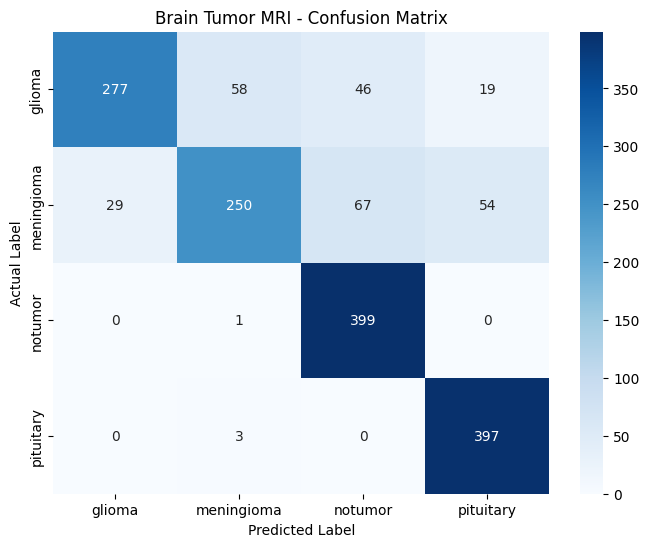

In [21]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import classification_report, confusion_matrix

# Predictions
test_generator.reset()
pred_probs = best_model.predict(test_generator)

y_pred = np.argmax(pred_probs, axis=1)
y_true = test_generator.classes

class_names = list(test_generator.class_indices.keys())

# Classification report
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Brain Tumor MRI - Confusion Matrix")
plt.show()

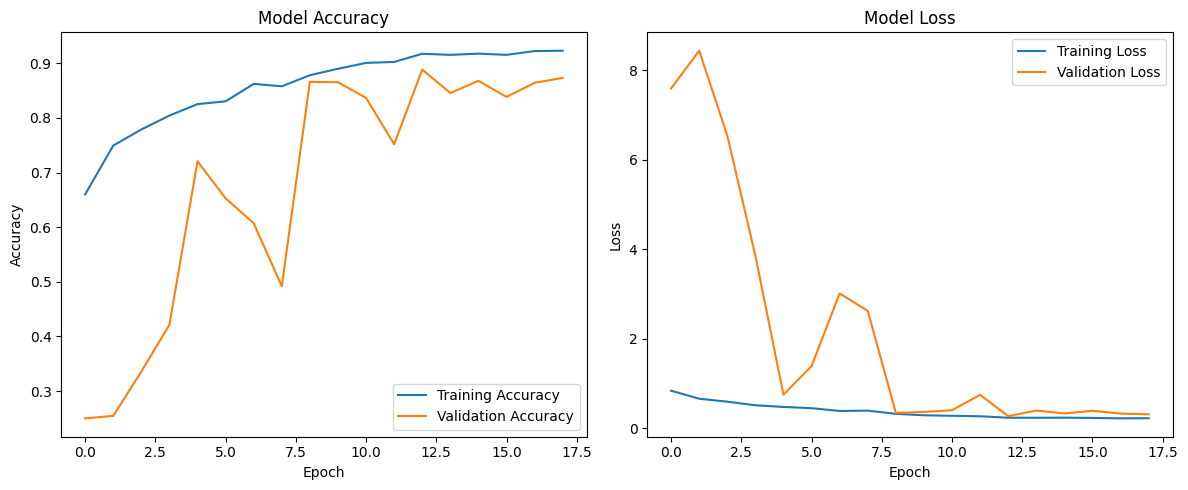

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [23]:
for layer in best_model.layers:
    print(layer.name, layer.output.shape)

conv2d_4 (None, 222, 222, 32)
max_pooling2d_4 (None, 111, 111, 32)
conv2d_5 (None, 109, 109, 64)
batch_normalization_3 (None, 109, 109, 64)
max_pooling2d_5 (None, 54, 54, 64)
conv2d_6 (None, 52, 52, 128)
batch_normalization_4 (None, 52, 52, 128)
max_pooling2d_6 (None, 26, 26, 128)
conv2d_7 (None, 24, 24, 256)
batch_normalization_5 (None, 24, 24, 256)
max_pooling2d_7 (None, 12, 12, 256)
global_average_pooling2d_1 (None, 256)
dense_2 (None, 128)
dropout_1 (None, 128)
dense_3 (None, 4)


1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step


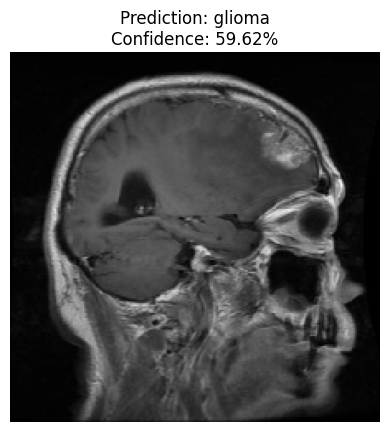

Predicted Class: glioma
Confidence: 59.62 %


In [24]:
import numpy as np
import matplotlib.pyplot as plt
import random
import glob
from tensorflow.keras.preprocessing.image import load_img, img_to_array

# Select one random MRI image from test dataset
image_paths = glob.glob(
    "/content/brain_tumor_dataset/Testing/*/*"
)

image_path = random.choice(image_paths)

# Load and preprocess image
img = load_img(
    image_path,
    target_size=(224, 224),
    color_mode="rgb"
)

img_array = img_to_array(img)
img_array = img_array / 255.0
img_array = np.expand_dims(img_array, axis=0)

# Predict
prediction = best_model.predict(img_array)

predicted_class_index = np.argmax(prediction)
class_names = list(test_generator.class_indices.keys())

predicted_class = class_names[predicted_class_index]
confidence = np.max(prediction) * 100

# Display image and prediction
plt.imshow(img)
plt.axis("off")
plt.title(
    f"Prediction: {predicted_class}\nConfidence: {confidence:.2f}%"
)
plt.show()

print("Predicted Class:", predicted_class)
print("Confidence:", round(confidence, 2), "%")

In [25]:
def predict_brain_tumor(image_path):

    img = load_img(
        image_path,
        target_size=(224, 224),
        color_mode="rgb"
    )

    img_array = img_to_array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    predictions = best_model.predict(img_array, verbose=0)

    class_names = list(test_generator.class_indices.keys())

    predicted_index = np.argmax(predictions)
    predicted_class = class_names[predicted_index]
    confidence = predictions[0][predicted_index] * 100

    plt.imshow(img)
    plt.axis("off")
    plt.title(f"{predicted_class} ({confidence:.2f}%)")
    plt.show()

    print("Predicted Class:", predicted_class)
    print("Confidence:", round(confidence, 2), "%")

    return predicted_class, confidence

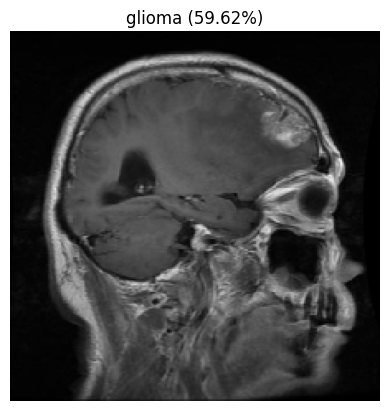

Predicted Class: glioma
Confidence: 59.62 %


('glioma', np.float32(59.615494))

In [26]:
predict_brain_tumor(image_path)

In [27]:
best_model.save("brain_tumor_cnn_model.keras")

print("Model saved successfully!")

Model saved successfully!


In [28]:
from google.colab import files

files.download("brain_tumor_cnn_model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>